Paths and reusable definitions were refactored. Stored outputs below are historical, not a fresh execution. See `docs/WORKFLOW.md` at the repository root before rerunning; several stages overwrite results or append Optuna trials.


In [ ]:
# Locate this checkout from the repository root or any notebook subdirectory.
from pathlib import Path
import sys

_root = next((p for p in (Path.cwd(), *Path.cwd().parents)
              if (p / "src" / "steam_recommender" / "paths.py").is_file()), None)
if _root is None:
    raise RuntimeError("Start Jupyter inside the repository checkout.")
sys.path.insert(0, str(_root / "src"))
from steam_recommender import paths as _paths
if Path(_paths.__file__).resolve() != (_root / "src/steam_recommender/paths.py").resolve():
    raise RuntimeError("A different checkout is cached; restart the kernel.")
from steam_recommender.paths import project_root, project_path


In [2]:
# =========================
# SENSITIVITY ANALYSIS — ALS
# validation set only
# =========================

import sys
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

In [3]:
import os

os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"

In [4]:
# modules import
from steam_recommender.als import ALSPipeline
from steam_recommender.splitting import random_user_split_train_val
from steam_recommender.confidence import linear_signal, log_signal, log_saturated_signal, make_log_inside_beta_signal

In [5]:
# =========================
# PATHS
# =========================

data_dir = os.path.join(str(project_path("data/processed")))
optuna_results_dir = os.path.join(str(project_path("results/optuna")))

sensitivity_results_dir = os.path.join(str(project_path("results/sensitivity")))
os.makedirs(sensitivity_results_dir, exist_ok=True)

best_configs_path = os.path.join(
    optuna_results_dir,
    "best_als_configs.csv"
)

alpha_sensitivity_path = os.path.join(
    sensitivity_results_dir,
    "sensitivity_alpha_mean_signal.csv"
)

beta_sensitivity_path = os.path.join(
    sensitivity_results_dir,
    "sensitivity_beta_log_inside.csv"
)

In [6]:

# =========================
# LOAD DATA
# =========================

train_val_df = pd.read_csv(
    os.path.join(data_dir, "users_items_filtered_train_val.csv")
)

train_val_df["user_id"] = train_val_df["user_id"].astype(str)
train_val_df["item_id"] = train_val_df["item_id"].astype(str)

best_configs = pd.read_csv(best_configs_path)

display(best_configs)



C:\Users\misie\AppData\Local\Temp\ipykernel_2916\1233213878.py:5: DtypeWarning: Columns (0: user_id) have mixed types. Specify dtype option on import or set low_memory=False.
  train_val_df = pd.read_csv(


,model,function,factors,iterations,alpha,beta,regularization,validation_ndcg,study_name,n_trials
0,ALS-linear,linear,80,30,9.948124e-07,NaN,0.003588,0.248913,als_linear,150
1,ALS-log,log,24,30,5.713901e-04,NaN,0.130920,0.261320,als_log,150
2,ALS-log-saturation,log_saturation,24,30,2.439038e-02,NaN,0.169714,0.261400,als_log_saturation,150
3,ALS-log-inside-beta,log_inside_beta,48,30,3.891845e-01,108.283984,0.010565,0.275349,als_log_inside_beta,150


In [7]:
# =========================
# TRAIN / VAL SPLIT
# same validation split as Optuna
# =========================

train_df, val_df = random_user_split_train_val(
    train_val_df,
    val_frac=0.1,
    seed=42
)

In [9]:
# =========================
# HELPERS
# =========================

from steam_recommender.confidence import get_sensitivity_signal as get_signal_fn


from steam_recommender.confidence import mean_signal_strength


def make_alpha_grid(function_name):
    if function_name == "linear":
        return np.concatenate([
            np.array([0.0]),
            np.logspace(-9, -3, 25)
        ])

    if function_name == "log":
        return np.logspace(-6, -1, 25)

    if function_name == "log_saturation":
        return np.logspace(-4, 1, 25)

    if function_name == "log_inside_beta":
        return np.logspace(-3, 0, 25)

    raise ValueError(f"Unknown function: {function_name}")


In [9]:
alpha_rows = []

for _, config in best_configs.iterrows():
    model_name = config["model"]
    function_name = config["function"]

    factors = int(config["factors"])
    iterations = int(config["iterations"])
    regularization = float(config["regularization"])

    beta = config["beta"] if "beta" in config and not pd.isna(config["beta"]) else None

    alpha_grid = make_alpha_grid(function_name)

    print("\n=========================")
    print(f"Alpha sensitivity: {model_name}")
    print(f"Function: {function_name}")
    print(f"factors={factors}, iterations={iterations}, reg={regularization}, beta={beta}")

    for alpha in tqdm(alpha_grid, desc=model_name):
        signal_fn = get_signal_fn(function_name, beta=beta)

        pipeline = ALSPipeline(
            factors=factors,
            iterations=iterations,
            alpha=float(alpha),
            regularization=regularization,
            random_state=0,
            signal_strength_fn=signal_fn,
            num_threads=8,
        )

        pipeline.fit(train_df, val_df)

        ndcg = pipeline.evaluate_fast(K=10)

        mss = mean_signal_strength(
            train_df=train_df,
            signal_fn=signal_fn,
            alpha=float(alpha)
        )

        alpha_rows.append({
            "model": model_name,
            "function": function_name,
            "alpha": float(alpha),
            "beta": beta,
            "factors": factors,
            "iterations": iterations,
            "regularization": regularization,
            "validation_ndcg@10": float(ndcg),
            "mean_signal_strength": float(mss),
        })


alpha_sensitivity_df = pd.DataFrame(alpha_rows)

alpha_sensitivity_df.to_csv(
    alpha_sensitivity_path,
    index=False
)

display(alpha_sensitivity_df.head())
print(f"Saved alpha sensitivity to: {alpha_sensitivity_path}")


Alpha sensitivity: ALS-linear
Function: linear
factors=80, iterations=30, reg=0.0035878904678559, beta=None


ALS-linear:   0%|          | 0/26 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

...

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

,model,function,alpha,beta,factors,iterations,regularization,validation_ndcg@10,mean_signal_strength
0,ALS-linear,linear,0.000000e+00,NaN,80,30,0.003588,0.248863,1.000000
1,ALS-linear,linear,1.000000e-09,NaN,80,30,0.003588,0.248883,1.000001
2,ALS-linear,linear,1.778279e-09,NaN,80,30,0.003588,0.248864,1.000002
3,ALS-linear,linear,3.162278e-09,NaN,80,30,0.003588,0.248879,1.000003
4,ALS-linear,linear,5.623413e-09,NaN,80,30,0.003588,0.248877,1.000005


Saved alpha sensitivity to: D:\Studiowe\Licencjat\modele\sensitivity_results\sensitivity_alpha_mean_signal.csv


In [10]:
# =========================
# BETA SENSITIVITY
# only log_inside_beta
# extended sweep: beta 1 → 1_000_000
# =========================

beta_rows = []

log_inside_config = best_configs[
    best_configs["function"] == "log_inside_beta"
].iloc[0]

model_name = log_inside_config["model"]
function_name = log_inside_config["function"]

factors = int(log_inside_config["factors"])
iterations = int(log_inside_config["iterations"])
alpha = float(log_inside_config["alpha"])
regularization = float(log_inside_config["regularization"])

# Rozszerzony zakres:
# 1 → 1_000_000
# Celem jest sprawdzenie, czy dla bardzo dużej bety wynik zacznie spadać,
# czyli czy całkowite spłaszczenie wpływu playtime pogarsza rekomendacje.
beta_grid = np.logspace(0, 6, 40)

print("\n=========================")
print("Beta sensitivity: ALS-log-inside-beta")
print(f"factors={factors}, iterations={iterations}, alpha={alpha}, reg={regularization}")
print(f"beta range: {beta_grid.min():.2e} → {beta_grid.max():.2e}")
print(f"num points: {len(beta_grid)}")

for beta in tqdm(beta_grid, desc="beta sweep"):
    beta = float(beta)

    signal_fn = make_log_inside_beta_signal(beta)

    pipeline = ALSPipeline(
        factors=factors,
        iterations=iterations,
        alpha=alpha,
        regularization=regularization,
        random_state=0,
        signal_strength_fn=signal_fn,
        num_threads=8,
    )

    pipeline.fit(train_df, val_df)

    ndcg = pipeline.evaluate_fast(K=10)

    mss = mean_signal_strength(
        train_df=train_df,
        signal_fn=signal_fn,
        alpha=alpha
    )

    beta_rows.append({
        "model": model_name,
        "function": function_name,
        "alpha": alpha,
        "beta": beta,
        "factors": factors,
        "iterations": iterations,
        "regularization": regularization,
        "validation_ndcg@10": float(ndcg),
        "mean_signal_strength": float(mss),
    })


beta_sensitivity_df = pd.DataFrame(beta_rows)

beta_sensitivity_df.to_csv(
    beta_sensitivity_path,
    index=False
)

display(beta_sensitivity_df)

print(f"Saved beta sensitivity to: {beta_sensitivity_path}")

print("\nBest beta sensitivity point:")
display(
    beta_sensitivity_df
    .sort_values("validation_ndcg@10", ascending=False)
    .head(10)
)


Beta sensitivity: ALS-log-inside-beta
factors=48, iterations=30, alpha=0.3891845053119486, reg=0.0105654679438528
beta range: 1.00e+00 → 1.00e+06
num points: 40


beta sweep:   0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

...

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

,model,function,alpha,beta,factors,iterations,regularization,validation_ndcg@10,mean_signal_strength
0,ALS-log-inside-beta,log_inside_beta,0.389185,1.000000,48,30,0.010565,0.242746,2.406244
1,ALS-log-inside-beta,log_inside_beta,0.389185,1.425103,48,30,0.010565,0.244967,2.436617
2,ALS-log-inside-beta,log_inside_beta,0.389185,2.030918,48,30,0.010565,0.247508,2.472259
3,ALS-log-inside-beta,log_inside_beta,0.389185,2.894266,48,30,0.010565,0.251002,2.513025
4,ALS-log-inside-beta,log_inside_beta,0.389185,4.124626,48,30,0.010565,0.255640,2.558637
5,ALS-log-inside-beta,log_inside_beta,0.389185,5.878016,48,30,0.010565,0.259217,2.608771
6,ALS-log-inside-beta,log_inside_beta,0.389185,8.376776,48,30,0.010565,0.261667,2.663134
7,ALS-log-inside-beta,log_inside_beta,0.389185,11.937766,48,30,0.010565,0.263613,2.721518
8,ALS-log-inside-beta,log_inside_beta,0.389185,17.012543,48,30,0.010565,0.265900,2.783815
9,ALS-log-inside-beta,log_inside_beta,0.389185,24.244620,48,30,0.010565,0.267952,2.850012


Saved beta sensitivity to: D:\Studiowe\Licencjat\modele\sensitivity_results\sensitivity_beta_log_inside.csv

Best beta sensitivity point:


,model,function,alpha,beta,factors,iterations,regularization,validation_ndcg@10,mean_signal_strength
18,ALS-log-inside-beta,log_inside_beta,0.389185,587.801607,48,30,0.010565,0.277468,3.638188
17,ALS-log-inside-beta,log_inside_beta,0.389185,412.462638,48,30,0.010565,0.277412,3.532665
19,ALS-log-inside-beta,log_inside_beta,0.389185,837.677640,48,30,0.010565,0.277318,3.747950
16,ALS-log-inside-beta,log_inside_beta,0.389185,289.426612,48,30,0.010565,0.277162,3.431575
20,ALS-log-inside-beta,log_inside_beta,0.389185,1193.776642,48,30,0.010565,0.276983,3.861695
21,ALS-log-inside-beta,log_inside_beta,0.389185,1701.254280,48,30,0.010565,0.276759,3.979113
15,ALS-log-inside-beta,log_inside_beta,0.389185,203.091762,48,30,0.010565,0.276704,3.335039
22,ALS-log-inside-beta,log_inside_beta,0.389185,2424.462017,48,30,0.010565,0.276417,4.099859
14,ALS-log-inside-beta,log_inside_beta,0.389185,142.510267,48,30,0.010565,0.276332,3.243105
23,ALS-log-inside-beta,log_inside_beta,0.389185,3455.107295,48,30,0.010565,0.276035,4.223567


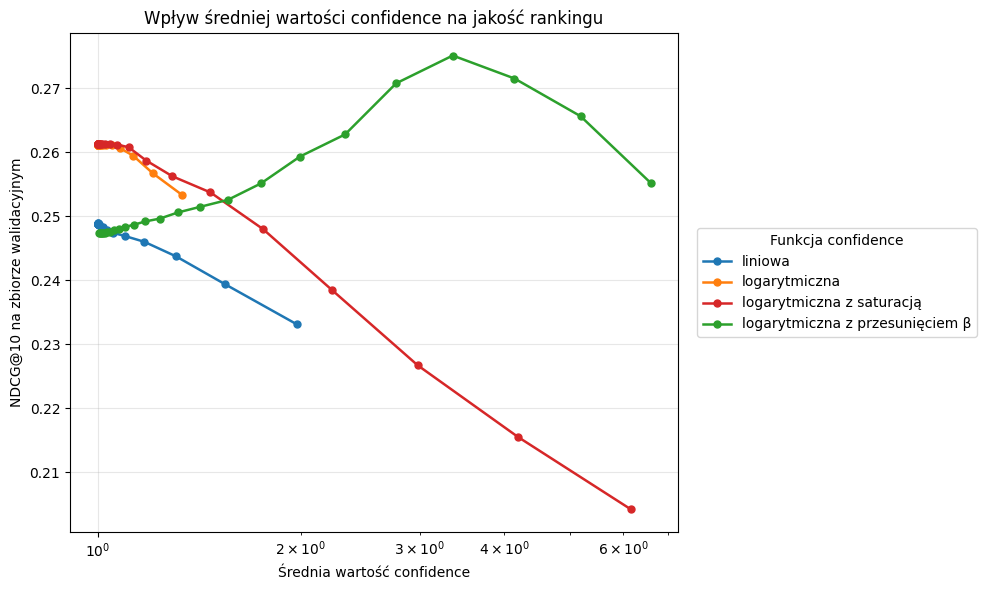

Zapisano: D:\Studiowe\Licencjat\modele\figures\wrazliwosc_ndcg_vs_srednie_confidence.png


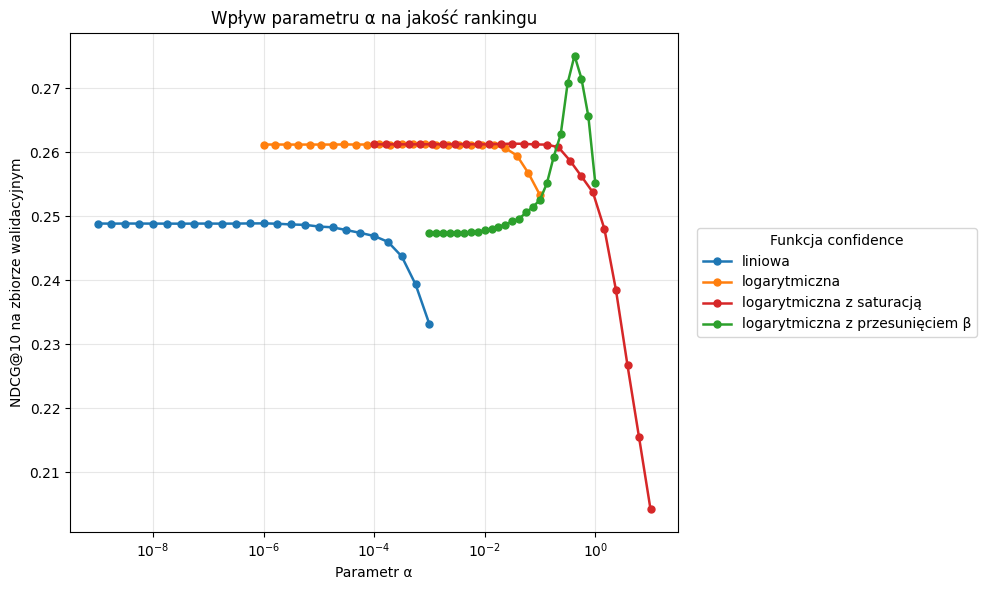

Zapisano: D:\Studiowe\Licencjat\modele\figures\wrazliwosc_ndcg_vs_alpha.png


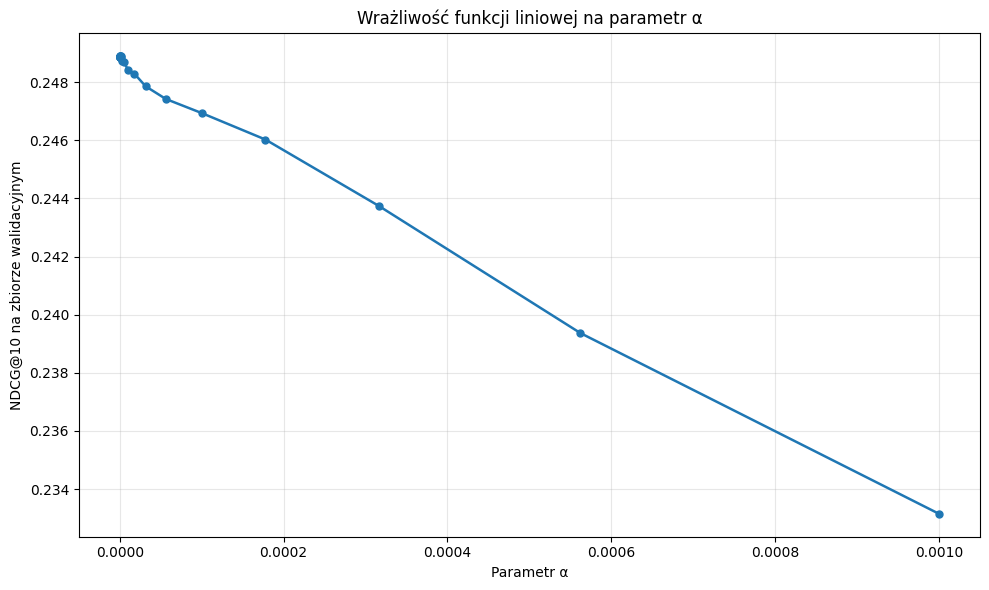

Zapisano: D:\Studiowe\Licencjat\modele\figures\wrazliwosc_liniowa_alpha_z_zerem.png


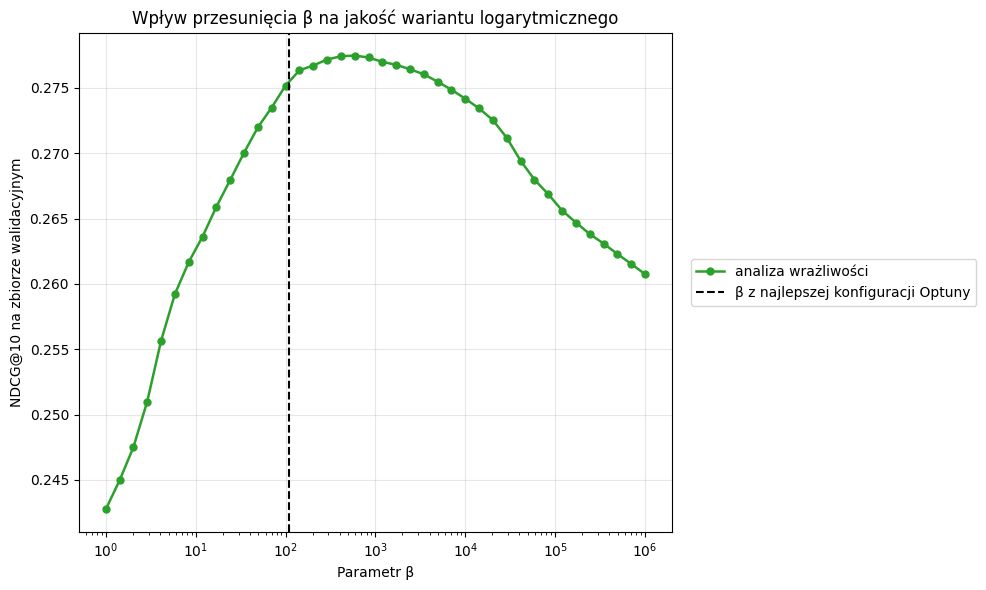

Zapisano: D:\Studiowe\Licencjat\modele\figures\wrazliwosc_log_beta_ndcg_vs_beta.png


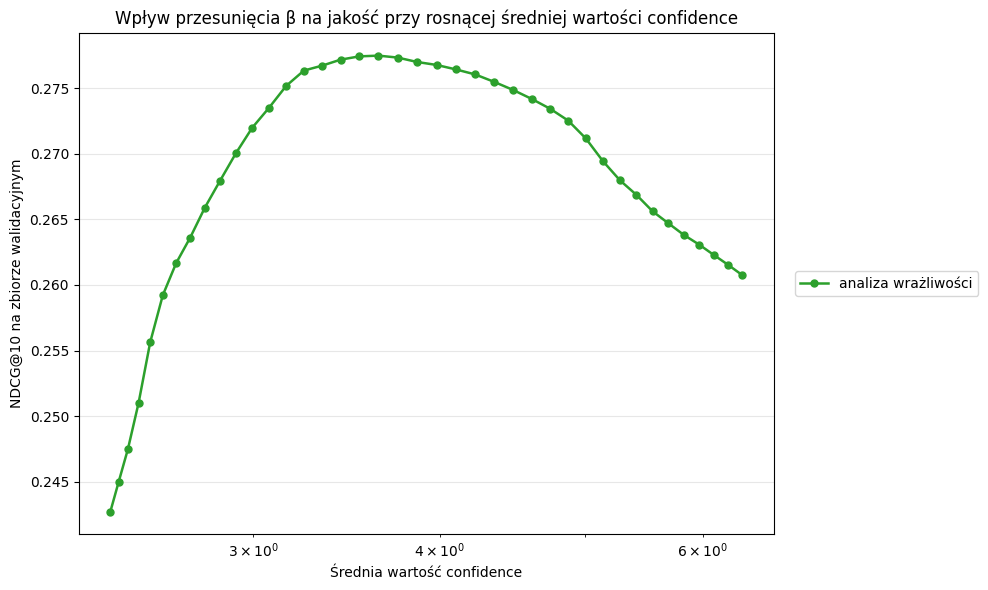

Zapisano: D:\Studiowe\Licencjat\modele\figures\wrazliwosc_log_beta_ndcg_vs_srednie_confidence.png

Najlepszy punkt analizy alpha dla każdej funkcji:


,model,function,alpha,beta,mean_signal_strength,validation_ndcg@10,factors,regularization
72,ALS-log-inside-beta,log_inside_beta,0.421697,108.283984,3.356677,0.275149,48,0.010565
88,ALS-log-saturation,log_saturation,0.031623,NaN,1.016331,0.261367,24,0.169714
40,ALS-log,log,0.000825,NaN,1.002757,0.261316,24,0.130920
13,ALS-linear,linear,0.000001,NaN,1.000970,0.248905,80,0.003588



Najlepsze punkty analizy beta:


,model,function,alpha,beta,mean_signal_strength,validation_ndcg@10,factors,regularization
18,ALS-log-inside-beta,log_inside_beta,0.389185,587.801607,3.638188,0.277468,48,0.010565
17,ALS-log-inside-beta,log_inside_beta,0.389185,412.462638,3.532665,0.277412,48,0.010565
19,ALS-log-inside-beta,log_inside_beta,0.389185,837.677640,3.747950,0.277318,48,0.010565
16,ALS-log-inside-beta,log_inside_beta,0.389185,289.426612,3.431575,0.277162,48,0.010565
20,ALS-log-inside-beta,log_inside_beta,0.389185,1193.776642,3.861695,0.276983,48,0.010565
21,ALS-log-inside-beta,log_inside_beta,0.389185,1701.254280,3.979113,0.276759,48,0.010565
15,ALS-log-inside-beta,log_inside_beta,0.389185,203.091762,3.335039,0.276704,48,0.010565
22,ALS-log-inside-beta,log_inside_beta,0.389185,2424.462017,4.099859,0.276417,48,0.010565
14,ALS-log-inside-beta,log_inside_beta,0.389185,142.510267,3.243105,0.276332,48,0.010565
23,ALS-log-inside-beta,log_inside_beta,0.389185,3455.107295,4.223567,0.276035,48,0.010565


In [17]:
# =========================
# WYKRESY ANALIZY WRAŻLIWOŚCI
# wersja uporządkowana:
# - stałe kolory modeli
# - "offset" -> "przesunięcie"
# - bez gwiazdek
# - na beta tylko linia dla najlepszej konfiguracji Optuny
# =========================

import os
import pandas as pd
import matplotlib.pyplot as plt


# =========================
# ŚCIEŻKI
# =========================


sensitivity_results_dir = os.path.join(str(project_path("results/sensitivity")))
optuna_results_dir = os.path.join(str(project_path("results/optuna")))
figures_dir = os.path.join(str(project_path("results/figures")))

os.makedirs(figures_dir, exist_ok=True)

alpha_sensitivity_path = os.path.join(
    sensitivity_results_dir,
    "sensitivity_alpha_mean_signal.csv"
)

beta_sensitivity_path = os.path.join(
    sensitivity_results_dir,
    "sensitivity_beta_log_inside.csv"
)

best_configs_path = os.path.join(
    optuna_results_dir,
    "best_als_configs.csv"
)


# =========================
# WCZYTANIE DANYCH
# =========================

alpha_df = pd.read_csv(alpha_sensitivity_path)
beta_df = pd.read_csv(beta_sensitivity_path)
best_configs = pd.read_csv(best_configs_path)

alpha_df = alpha_df.sort_values(
    by=["function", "mean_signal_strength"]
).reset_index(drop=True)

beta_df = beta_df.sort_values(
    by="beta"
).reset_index(drop=True)


# =========================
# ETYKIETY I KOLORY
# =========================

function_labels = {
    "linear": "liniowa",
    "log": "logarytmiczna",
    "log_saturation": "logarytmiczna z saturacją",
    "log_inside_beta": "logarytmiczna z przesunięciem β",
}

function_order = [
    "linear",
    "log",
    "log_saturation",
    "log_inside_beta",
]

function_colors = {
    "linear": "tab:blue",
    "log": "tab:orange",
    "log_saturation": "tab:red",
    "log_inside_beta": "tab:green",
}


# =========================
# 1. NDCG vs ŚREDNIA WARTOŚĆ CONFIDENCE
# =========================

plt.figure(figsize=(10, 6))

for function_name in function_order:
    group = alpha_df[alpha_df["function"] == function_name].copy()

    if len(group) == 0:
        continue

    group = group.sort_values("mean_signal_strength")

    plt.plot(
        group["mean_signal_strength"],
        group["validation_ndcg@10"],
        marker="o",
        linewidth=1.8,
        markersize=5,
        color=function_colors[function_name],
        label=function_labels.get(function_name, function_name),
    )

plt.xscale("log")
plt.xlabel("Średnia wartość confidence")
plt.ylabel("NDCG@10 na zbiorze walidacyjnym")
plt.title("Wpływ średniej wartości confidence na jakość rankingu")

plt.legend(
    title="Funkcja confidence",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
)

plt.grid(True, alpha=0.3)
plt.tight_layout()

path = os.path.join(
    figures_dir,
    "wrazliwosc_ndcg_vs_srednie_confidence.png"
)

plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Zapisano: {path}")


# =========================
# 2. NDCG vs ALPHA
# =========================

plt.figure(figsize=(10, 6))

for function_name in function_order:
    group = alpha_df[alpha_df["function"] == function_name].copy()

    if len(group) == 0:
        continue

    group = group.sort_values("alpha")

    # alpha=0 nie działa na skali log, więc na tym wykresie pomijamy 0
    group_plot = group[group["alpha"] > 0]

    plt.plot(
        group_plot["alpha"],
        group_plot["validation_ndcg@10"],
        marker="o",
        linewidth=1.8,
        markersize=5,
        color=function_colors[function_name],
        label=function_labels.get(function_name, function_name),
    )

plt.xscale("log")
plt.xlabel("Parametr α")
plt.ylabel("NDCG@10 na zbiorze walidacyjnym")
plt.title("Wpływ parametru α na jakość rankingu")

plt.legend(
    title="Funkcja confidence",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
)

plt.grid(True, alpha=0.3)
plt.tight_layout()

path = os.path.join(
    figures_dir,
    "wrazliwosc_ndcg_vs_alpha.png"
)

plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Zapisano: {path}")


# =========================
# 3. FUNKCJA LINIOWA — Z ALPHA = 0
# =========================

linear_df = alpha_df[alpha_df["function"] == "linear"].copy()
linear_df = linear_df.sort_values("alpha")

plt.figure(figsize=(10, 6))

plt.plot(
    linear_df["alpha"],
    linear_df["validation_ndcg@10"],
    marker="o",
    linewidth=1.8,
    markersize=5,
    color=function_colors["linear"],
)

plt.xlabel("Parametr α")
plt.ylabel("NDCG@10 na zbiorze walidacyjnym")
plt.title("Wrażliwość funkcji liniowej na parametr α")
plt.grid(True, alpha=0.3)
plt.tight_layout()

path = os.path.join(
    figures_dir,
    "wrazliwosc_liniowa_alpha_z_zerem.png"
)

plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Zapisano: {path}")


# =========================
# 4. WRAŻLIWOŚĆ NA BETA — NDCG vs BETA
# =========================

log_inside_best = best_configs[
    best_configs["function"] == "log_inside_beta"
].iloc[0]

best_beta = float(log_inside_best["beta"])

plt.figure(figsize=(10, 6))

plt.plot(
    beta_df["beta"],
    beta_df["validation_ndcg@10"],
    marker="o",
    linewidth=1.8,
    markersize=5,
    color=function_colors["log_inside_beta"],
    label="analiza wrażliwości",
)

plt.axvline(
    best_beta,
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="β z najlepszej konfiguracji Optuny",
)

plt.xscale("log")
plt.xlabel("Parametr β")
plt.ylabel("NDCG@10 na zbiorze walidacyjnym")
plt.title("Wpływ przesunięcia β na jakość wariantu logarytmicznego")

plt.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
)

plt.grid(True, alpha=0.3)
plt.tight_layout()

path = os.path.join(
    figures_dir,
    "wrazliwosc_log_beta_ndcg_vs_beta.png"
)

plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Zapisano: {path}")


# =========================
# 5. WRAŻLIWOŚĆ NA BETA — NDCG vs ŚREDNIA WARTOŚĆ CONFIDENCE
# =========================

plt.figure(figsize=(10, 6))

plt.plot(
    beta_df["mean_signal_strength"],
    beta_df["validation_ndcg@10"],
    marker="o",
    linewidth=1.8,
    markersize=5,
    color=function_colors["log_inside_beta"],
    label="analiza wrażliwości",
)

plt.xscale("log")
plt.xlabel("Średnia wartość confidence")
plt.ylabel("NDCG@10 na zbiorze walidacyjnym")
plt.title("Wpływ przesunięcia β na jakość przy rosnącej średniej wartości confidence")

plt.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
)

plt.grid(True, alpha=0.3)
plt.tight_layout()

path = os.path.join(
    figures_dir,
    "wrazliwosc_log_beta_ndcg_vs_srednie_confidence.png"
)

plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Zapisano: {path}")


# =========================
# 6. PODSUMOWANIE — NAJLEPSZE PUNKTY
# =========================

print("\nNajlepszy punkt analizy alpha dla każdej funkcji:")
display(
    alpha_df
    .sort_values("validation_ndcg@10", ascending=False)
    .groupby("function")
    .head(1)
    [
        [
            "model",
            "function",
            "alpha",
            "beta",
            "mean_signal_strength",
            "validation_ndcg@10",
            "factors",
            "regularization",
        ]
    ]
    .sort_values("validation_ndcg@10", ascending=False)
)

print("\nNajlepsze punkty analizy beta:")
display(
    beta_df
    .sort_values("validation_ndcg@10", ascending=False)
    .head(10)
    [
        [
            "model",
            "function",
            "alpha",
            "beta",
            "mean_signal_strength",
            "validation_ndcg@10",
            "factors",
            "regularization",
        ]
    ]
)

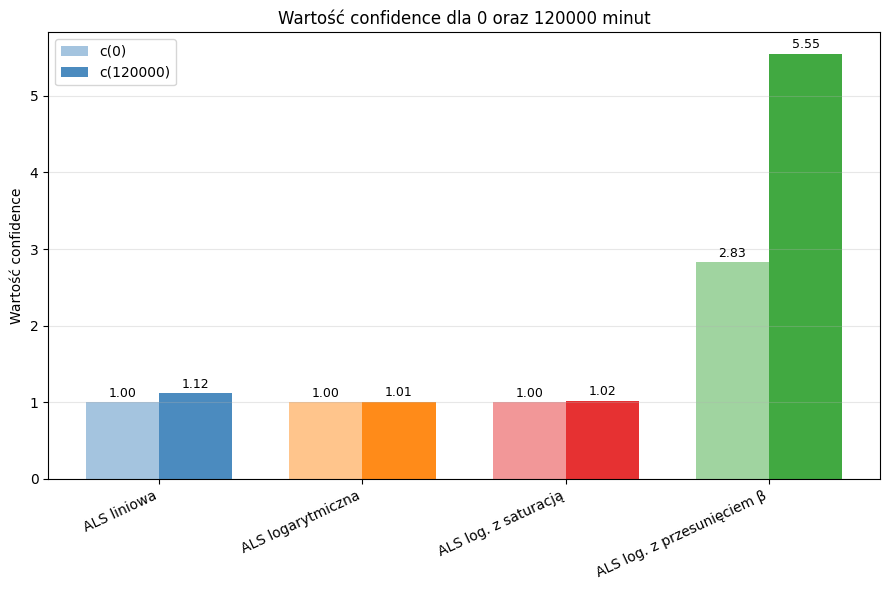

Zapisano: D:\Studiowe\Licencjat\modele\figures\confidence_levels_best_als.png


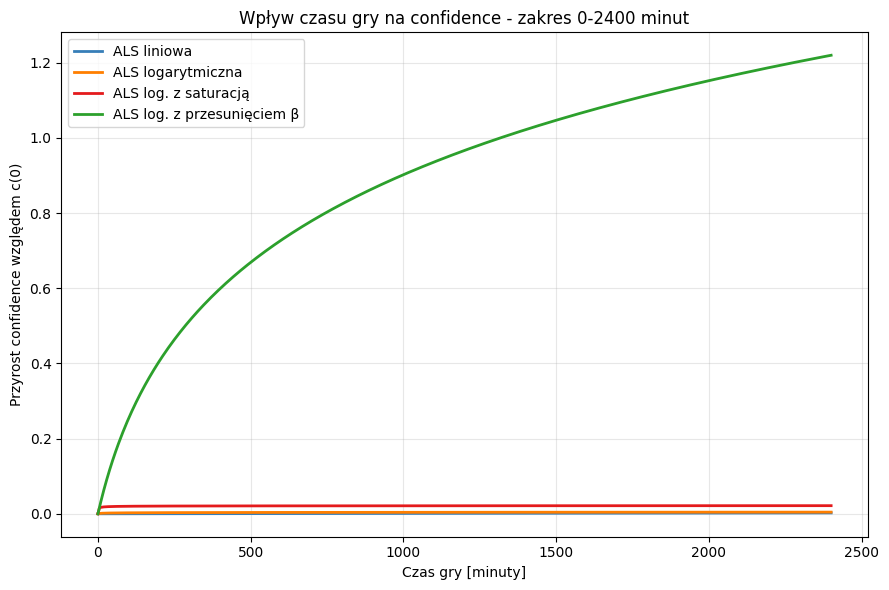

Zapisano: D:\Studiowe\Licencjat\modele\figures\confidence_growth_best_als_0_2400.png


In [7]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# PATHS
# ============================================================

figures_dir = os.path.join(str(project_path("results/figures")))
optuna_results_dir = os.path.join(str(project_path("results/optuna")))

best_configs_path = os.path.join(optuna_results_dir, "best_als_configs.csv")

os.makedirs(figures_dir, exist_ok=True)

# ============================================================
# LOAD BEST CONFIGS
# ============================================================

best_configs = pd.read_csv(best_configs_path)

# ============================================================
# FUNCTION LABELS
# ============================================================

function_labels = {
    "linear": "ALS liniowa",
    "log": "ALS logarytmiczna",
    "log_saturation": "ALS log. z saturacją",
    "log_inside_beta": "ALS log. z przesunięciem β",
}

function_colors = {
    "linear": "#377eb8",
    "log": "#ff7f00",
    "log_saturation": "#e41a1c",
    "log_inside_beta": "#2ca02c",
}

# ============================================================
# CONFIDENCE FUNCTIONS
# ============================================================

def confidence_linear(r, alpha, beta=None):
    return 1 + alpha * r

def confidence_log(r, alpha, beta=None):
    return 1 + alpha * np.log1p(r)

def confidence_log_saturation(r, alpha, beta=None):
    x = np.log1p(r)
    return 1 + alpha * (x / (1 + x))

def confidence_log_inside_beta(r, alpha, beta):
    return 1 + alpha * np.log1p(r + beta)

confidence_fn_map = {
    "linear": confidence_linear,
    "log": confidence_log,
    "log_saturation": confidence_log_saturation,
    "log_inside_beta": confidence_log_inside_beta,
}

# ============================================================
# PREPARE DATA FROM BEST CONFIGS
# ============================================================

plot_rows = []

for _, row in best_configs.iterrows():
    function_name = row["function"]
    alpha = float(row["alpha"])
    beta = row["beta"] if "beta" in row and not pd.isna(row["beta"]) else None

    fn = confidence_fn_map[function_name]

    c0 = fn(0, alpha, beta)
    c120000 = fn(120000, alpha, beta)

    plot_rows.append({
        "function": function_name,
        "label": function_labels[function_name],
        "alpha": alpha,
        "beta": beta,
        "c0": c0,
        "c120000": c120000,
        "color": function_colors[function_name],
    })

plot_df = pd.DataFrame(plot_rows)

# ============================================================
# FIGURE 1
# Wartość confidence dla 0 i 120000 minut
# ============================================================

x = np.arange(len(plot_df))
width = 0.36

plt.figure(figsize=(9, 6))

bars1 = plt.bar(
    x - width / 2,
    plot_df["c0"],
    width=width,
    color=plot_df["color"],
    alpha=0.45,
    label="c(0)",
)

bars2 = plt.bar(
    x + width / 2,
    plot_df["c120000"],
    width=width,
    color=plot_df["color"],
    alpha=0.90,
    label="c(120000)",
)

plt.xticks(x, plot_df["label"], rotation=25, ha="right")
plt.ylabel("Wartość confidence")
plt.title("Wartość confidence dla 0 oraz 120000 minut")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.03,
            f"{height:.2f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )

path1 = os.path.join(figures_dir, "confidence_levels_best_als.png")
plt.savefig(path1, dpi=300, bbox_inches="tight")
plt.show()

print(f"Zapisano: {path1}")

# ============================================================
# FIGURE 2
# Przyrost confidence względem c(0) dla zakresu 0-2400 minut
# ============================================================

minutes = np.linspace(0, 2400, 500)

plt.figure(figsize=(9, 6))

for _, row in plot_df.iterrows():
    function_name = row["function"]
    alpha = row["alpha"]
    beta = row["beta"]
    fn = confidence_fn_map[function_name]

    c_values = fn(minutes, alpha, beta)
    c0 = fn(0, alpha, beta)
    delta_values = c_values - c0

    plt.plot(
        minutes,
        delta_values,
        label=row["label"],
        color=row["color"],
        linewidth=2,
    )

plt.xlabel("Czas gry [minuty]")
plt.ylabel("Przyrost confidence względem c(0)")
plt.title("Wpływ czasu gry na confidence - zakres 0-2400 minut")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

path2 = os.path.join(figures_dir, "confidence_growth_best_als_0_2400.png")
plt.savefig(path2, dpi=300, bbox_inches="tight")
plt.show()

print(f"Zapisano: {path2}")